In [ ]:

# ============================================================
# TCC — MODELO 4
# PIM-PF COM VARIAÇÃO CAMBIAL
# ============================================================

pacotes <- c(
  "lmtest",
  "sandwich",
  "strucchange"
)

faltantes <- pacotes[
  !vapply(
    pacotes,
    requireNamespace,
    logical(1),
    quietly = TRUE
  )
]

if (length(faltantes) > 0) {
  install.packages(
    faltantes,
    repos = "https://cloud.r-project.org"
  )
}

invisible(lapply(
  pacotes,
  library,
  character.only = TRUE
))

cat("Pacotes carregados com sucesso.\n")


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Pacotes carregados com sucesso.


In [ ]:

# MODELO 4 - PIM-PF + CAMBIO

install.packages("lmtest")
install.packages("sandwich")

# 1. Inserção dos dados

Data <- seq(
  from = as.Date("1999-06-01"),
  to = as.Date("2026-07-01"),
  by = "month"
)

Selic <- c(
21,
19.5,
19.5,
19,
19,
19,
19,
19,
19,
18.5,
18.5,
18.5,
17.5,
16.5,
16.5,
16.5,
16.5,
16.5,
15.75,
15.25,
15.25,
15.75,
16.25,
16.75,
18.25,
19,
19,
19,
19,
19,
19,
19,
18.75,
18.5,
18.5,
18.5,
18.5,
18,
18,
18,
21,
22,
25,
25.5,
26.5,
26.5,
26.5,
26.5,
26,
24.5,
22,
20,
19,
17.5,
16.5,
16.5,
16.5,
16.25,
16,
16,
16,
16,
16,
16.25,
16.75,
17.25,
17.75,
18.25,
18.75,
19.25,
19.5,
19.75,
19.75,
19.75,
19.75,
19.5,
19,
18.5,
18,
17.25,
17.25,
16.5,
15.75,
15.75,
15.25,
14.75,
14.25,
14.25,
13.75,
13.25,
13.25,
13,
13,
12.75,
12.5,
12.5,
12,
11.5,
11.5,
11.25,
11.25,
11.25,
11.25,
11.25,
11.25,
11.25,
11.75,
11.75,
12.25,
13,
13,
13.75,
13.75,
13.75,
13.75,
12.75,
12.75,
11.25,
10.25,
10.25,
9.25,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
9.5,
9.5,
10.25,
10.75,
10.75,
10.75,
10.75,
10.75,
10.75,
11.25,
11.25,
11.75,
12,
12,
12.25,
12.5,
12.5,
12,
11.5,
11.5,
11,
10.5,
10.5,
9.75,
9,
8.5,
8.5,
8,
7.5,
7.5,
7.25,
7.25,
7.25,
7.25,
7.25,
7.25,
7.5,
8,
8,
8.5,
9,
9,
9.5,
10,
10,
10.5,
10.75,
10.75,
11,
11,
11,
11,
11,
11,
11.25,
11.25,
11.75,
12.25,
12.25,
12.75,
13.25,
13.25,
13.75,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14,
14,
13.75,
13,
12.25,
12.25,
11.25,
11.25,
10.25,
9.25,
9.25,
8.25,
7.5,
7.5,
7,
7,
6.75,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6,
5.5,
5,
5,
4.5,
4.5,
4.25,
3.75,
3.75,
3,
2.25,
2.25,
2,
2,
2,
2,
2,
2,
2,
2.75,
2.75,
3.5,
4.25,
4.25,
5.25,
6.25,
7.75,
7.75,
9.25,
9.25,
10.75,
11.75,
11.75,
12.75,
13.25,
13.25,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.25,
12.75,
12.75,
12.25,
11.75,
11.75,
11.25,
10.75,
10.75,
10.5,
10.5,
10.5,
10.5,
10.75,
10.75,
11.25,
12.25,
13.25,
13.25,
14.25,
14.25,
14.75,
15,
15,
15,
15,
15,
15,
15,
15,
15,
14.75,
14.5,
14.5,
14.25,
14.25
)

Desvio_Inflacao <- c(
-4.68,
-3.43,
-2.31,
-1.75,
-0.50,
0.65,
0.94,
2.85,
1.86,
0.92,
0.77,
0.47,
0.51,
1.06,
1.86,
1.77,
0.65,
-0.01,
-0.03,
1.92,
2.27,
2.44,
2.61,
3.04,
3.35,
3.05,
2.41,
2.46,
3.19,
3.61,
3.67,
4.12,
4.01,
4.25,
4.48,
4.27,
4.16,
4.01,
3.96,
4.43,
4.95,
7.43,
9.03,
5.97,
7.35,
8.07,
8.27,
8.74,
8.07,
6.93,
6.57,
6.64,
5.48,
2.52,
0.80,
2.21,
1.19,
0.39,
-0.24,
-0.35,
0.56,
1.31,
1.68,
1.20,
1.36,
1.74,
2.10,
2.91,
2.89,
3.04,
3.57,
3.55,
2.77,
2.07,
1.52,
1.54,
1.86,
1.72,
1.19,
1.20,
1.01,
0.82,
0.13,
-0.27,
-0.47,
-0.53,
-0.66,
-0.80,
-1.24,
-1.48,
-1.36,
-1.51,
-1.48,
-1.54,
-1.50,
-1.32,
-0.81,
-0.76,
-0.32,
-0.35,
-0.38,
-0.31,
-0.04,
0.06,
0.11,
0.23,
0.54,
1.08,
1.56,
1.87,
1.67,
1.75,
1.91,
1.89,
1.40,
1.34,
1.40,
1.11,
1.03,
0.70,
0.30,
0.00,
-0.14,
-0.16,
-0.33,
-0.28,
-0.19,
0.09,
0.33,
0.67,
0.76,
0.72,
0.34,
0.10,
-0.01,
0.20,
0.70,
1.13,
1.41,
1.49,
1.51,
1.80,
2.01,
2.05,
2.21,
2.37,
2.73,
2.81,
2.47,
2.14,
2.00,
1.72,
1.34,
0.74,
0.60,
0.49,
0.42,
0.70,
0.74,
0.78,
0.95,
1.03,
1.34,
1.65,
1.81,
2.09,
1.99,
2.00,
2.20,
1.77,
1.59,
1.36,
1.34,
1.27,
1.41,
1.09,
1.18,
1.65,
1.78,
1.87,
2.02,
2.00,
2.01,
2.25,
2.09,
2.06,
1.91,
2.64,
3.20,
3.63,
3.67,
3.97,
4.39,
5.06,
5.03,
4.99,
5.43,
5.98,
6.17,
6.21,
5.86,
4.89,
4.78,
4.82,
4.34,
4.24,
4.47,
3.98,
3.37,
2.49,
1.79,
0.85,
0.26,
0.07,
-0.42,
-0.90,
-1.50,
-1.79,
-2.04,
-1.96,
-1.80,
-1.70,
-1.55,
-1.64,
-1.66,
-1.82,
-1.74,
-1.64,
-0.11,
-0.02,
-0.31,
0.03,
0.06,
-0.45,
-0.75,
-0.47,
-0.36,
0.33,
0.69,
0.41,
-0.88,
-1.03,
-0.82,
-1.36,
-1.71,
-0.98,
0.06,
0.19,
0.01,
-0.70,
-1.60,
-2.12,
-1.87,
-1.69,
-1.56,
-0.86,
-0.08,
0.31,
0.52,
0.81,
1.45,
2.35,
3.01,
4.31,
4.60,
5.24,
5.93,
6.50,
6.92,
6.99,
6.31,
6.88,
7.04,
7.80,
8.63,
8.23,
8.39,
6.57,
5.23,
3.67,
2.97,
2.40,
2.29,
2.52,
2.35,
1.40,
0.93,
0.69,
-0.09,
0.74,
1.36,
1.94,
1.57,
1.43,
1.37,
1.51,
1.50,
0.93,
0.69,
0.93,
1.23,
1.50,
1.24,
1.42,
1.76,
1.87,
1.83,
1.56,
2.06,
2.48,
2.53,
2.32,
2.35,
2.23,
2.13,
2.17,
1.68,
1.46,
1.26,
1.44,
0.81,
1.14,
1.39,
1.72,
1.64,
1.44
)

Hiato_PIM <- c(
-1.6998794,
-3.2371575,
-1.9337112,
-0.9745328,
0.3149088,
-0.7642423,
-0.2004376,
-1.4490867,
-1.6184281,
-0.3020120,
0.3312703,
-0.2413962,
1.9101846,
2.3502482,
2.0601362,
0.5848715,
2.5128226,
1.4155111,
5.7332810,
2.9487595,
3.7908837,
2.1246321,
1.5764837,
2.1697782,
0.7194311,
0.2942779,
0.1394658,
-1.9471356,
-4.3636961,
-3.4192311,
-3.3044838,
-0.5384528,
1.4347921,
0.8945154,
0.9323081,
0.6616141,
0.7306667,
0.9981433,
-0.2920869,
0.1578085,
0.2605049,
-0.0960560,
-0.5596583,
-0.5952905,
-1.2560347,
-1.7770636,
-2.1849398,
-3.8781780,
-3.6709131,
-4.8183938,
-3.9617869,
-1.0859867,
-1.2428924,
-0.6398065,
-2.1901746,
-0.8514494,
0.2664232,
0.5984027,
0.9362428,
1.4619632,
1.4844721,
1.8092925,
2.4276696,
2.6265613,
1.5246372,
1.1819061,
1.4789315,
1.5567541,
-0.1711278,
0.4517694,
0.1696192,
3.2690040,
0.7141897,
-0.1961418,
-0.3797461,
-1.3307495,
-2.1567191,
-1.5902351,
-0.2026120,
-0.1726578,
0.2905968,
-0.5954680,
-0.4544372,
0.0314007,
-1.5919411,
-1.1067243,
-1.5524435,
-2.8725561,
-2.2809250,
-1.3650003,
-1.0023268,
-1.4079060,
-0.4951295,
0.5824733,
1.3359696,
1.3453925,
1.7781419,
1.2121192,
2.4500528,
1.1001328,
3.9293146,
2.6488861,
2.7974286,
4.3659724,
4.0360130,
4.1131474,
4.1347393,
4.8447455,
6.0252933,
6.5249720,
5.2194889,
6.5024037,
3.4784846,
-2.9404882,
-13.6181122,
-11.8829175,
-9.9197279,
-9.5924129,
-8.4958100,
-7.5003072,
-6.2392573,
-5.2704243,
-3.9304906,
-2.7458220,
-0.8119165,
0.2218364,
0.4531245,
1.7129435,
1.3431720,
3.4911664,
3.6543912,
3.1542189,
2.5268701,
1.7232064,
1.2752994,
1.3214880,
0.8127892,
1.4415854,
1.7735844,
1.9519714,
3.0798825,
3.2691827,
0.6112237,
3.5856261,
1.5496617,
1.2952505,
0.5136238,
-1.1265293,
-2.2984034,
-1.8232149,
0.7667052,
-3.5211801,
-2.7863978,
-3.2258359,
-3.3150153,
-2.7584593,
-2.5397504,
-1.2329103,
0.8938341,
-1.0558476,
0.4939342,
-0.7668897,
-0.0702574,
0.9425978,
-1.8823490,
0.2028093,
2.0420973,
1.9110098,
2.4169678,
2.0864834,
2.5255377,
3.2219401,
2.3008292,
3.1746030,
-0.1477458,
1.8291082,
2.5679449,
2.4769865,
2.0455876,
1.4151107,
-1.1348966,
1.7671420,
2.5334943,
3.2480553,
3.6943016,
3.2853292,
1.0317680,
1.9071366,
1.4333356,
1.6027559,
0.0811223,
-0.5754315,
-0.7840954,
-2.1399643,
-1.2701587,
-3.0551668,
-2.8594795,
-4.0682665,
-5.0381789,
-3.9542538,
-4.5685264,
-3.7114393,
-3.3509681,
-2.7082820,
-3.8106597,
-2.8671615,
-4.3976511,
-3.2512431,
-4.5673710,
-3.3019932,
-1.5624117,
-0.7798689,
0.3489809,
-1.1075340,
-1.0873976,
-0.5559230,
0.3708861,
0.5734764,
0.6545793,
1.0270204,
1.9077060,
2.4207678,
5.1792733,
2.8418832,
2.1158331,
3.6993507,
4.0113985,
-7.2909362,
4.2898480,
3.9736101,
3.0891447,
0.1347895,
1.6572987,
1.6095072,
1.5169438,
1.0649843,
1.4622972,
0.9061201,
1.6432472,
1.6233214,
0.7782923,
0.3857624,
1.4474472,
1.4979690,
3.8971260,
1.5613017,
0.2313486,
1.5996314,
2.3961322,
-5.5087411,
-24.2052366,
-18.2134051,
-9.7788534,
-1.7302079,
1.2377735,
3.9711497,
5.5610031,
5.9413759,
5.4357615,
6.0220575,
4.5651237,
2.3488094,
0.3599943,
1.5095037,
1.1946902,
-0.2624049,
-0.3347806,
-0.7001028,
-1.1560806,
-1.0997387,
0.3867547,
0.1051618,
1.0216950,
0.1068790,
0.7179762,
0.1579312,
0.1118784,
1.0920412,
-0.3799177,
-2.0026609,
-0.5083972,
-0.5590341,
-0.4633043,
-0.7776911,
-1.0006969,
-0.3840549,
-0.9441588,
-0.3277912,
-0.7710206,
-1.4723633,
-1.0732760,
-1.5146486,
-1.2155790,
-0.2117673,
1.4517608,
-0.0018228,
-0.1474773,
0.0306791,
-0.3812037,
-1.9650813,
2.7878320,
1.0895193,
0.7368224,
1.5725931,
1.4868799,
0.8255969,
0.5864031,
0.3039442,
-0.2557282,
1.1694889,
0.4062713,
-0.5164656,
0.2835434,
-0.1488257,
0.6195263,
0.1026632,
0.0961065,
-0.1823821,
-2.2614410,
-0.3317375,
0.5068055,
0.5089144,
1.5618997,
0.4173964,
-1.2634182,
-1.3087565
)

# Vetor do cambio:
# Variacao logaritmica mensal do cambio (delta log E)
Cambio <- c(
0.0475023,
0.0195760,
0.0436907,
0.0092093,
0.0369263,
-0.0203115,
-0.0461820,
-0.0214460,
-0.0158707,
-0.0189355,
0.0149282,
0.0332057,
-0.0107806,
-0.0058235,
0.0063211,
0.0164459,
0.0217283,
0.0357442,
0.0078235,
-0.0044923,
0.0239623,
0.0425888,
0.0483570,
0.0466485,
0.0336432,
0.0372632,
0.0179244,
0.0621932,
0.0253159,
-0.0746471,
-0.0735788,
0.0064127,
0.0173845,
-0.0306348,
-0.0112279,
0.0666803,
0.0900037,
0.0781476,
0.0580837,
0.0719146,
0.1299831,
-0.0621958,
0.0137458,
-0.0530963,
0.0433688,
-0.0408997,
-0.1000590,
-0.0536807,
-0.0248347,
-0.0011799,
0.0417244,
-0.0269032,
-0.0211961,
0.0181121,
0.0039390,
-0.0254467,
0.0271544,
-0.0084993,
0.0001721,
0.0647536,
0.0092143,
-0.0299411,
-0.0112258,
-0.0379414,
-0.0133010,
-0.0237291,
-0.0246370,
-0.0093141,
-0.0359909,
0.0403261,
-0.0475117,
-0.0502490,
-0.0161523,
-0.0167123,
-0.0054498,
-0.0284445,
-0.0166564,
-0.0204605,
0.0332304,
-0.0050884,
-0.0505090,
-0.0045898,
-0.0106044,
0.0226596,
0.0317214,
-0.0265925,
-0.0153736,
0.0059196,
-0.0094511,
0.0044587,
-0.0037142,
-0.0053167,
-0.0199308,
-0.0036320,
-0.0275213,
-0.0251159,
-0.0254006,
-0.0257439,
0.0432410,
-0.0343577,
-0.0533013,
-0.0174190,
0.0090554,
-0.0065725,
-0.0266149,
-0.0117022,
-0.0110114,
-0.0169587,
-0.0253719,
-0.0171328,
0.0130476,
0.1099027,
0.1884983,
0.0420859,
0.0549841,
-0.0370113,
0.0022943,
0.0004755,
-0.0477556,
-0.0679928,
-0.0514235,
-0.0127495,
-0.0463821,
-0.0138611,
-0.0457615,
-0.0070427,
0.0138647,
0.0167138,
0.0341338,
-0.0307683,
-0.0164864,
0.0317131,
-0.0037020,
-0.0206377,
-0.0056670,
-0.0235183,
-0.0206932,
0.0175464,
-0.0116830,
-0.0109849,
-0.0041282,
-0.0053500,
-0.0448080,
0.0169384,
-0.0165603,
-0.0146627,
0.0209442,
0.0913746,
0.0129459,
0.0100475,
0.0255845,
-0.0260314,
-0.0406544,
0.0437785,
0.0326047,
0.0683457,
0.0313269,
-0.0100543,
0.0003450,
-0.0006408,
0.0008379,
0.0185480,
0.0048244,
-0.0227321,
-0.0288703,
0.0048027,
0.0097366,
0.0161510,
0.0657112,
0.0357988,
0.0391831,
-0.0310906,
-0.0367380,
0.0476451,
0.0215915,
0.0155258,
0.0006295,
-0.0244609,
-0.0409366,
-0.0053439,
0.0065524,
-0.0048878,
0.0193213,
0.0282137,
0.0482818,
0.0400718,
0.0350859,
-0.0019721,
0.0669154,
0.1085686,
-0.0311540,
0.0060607,
0.0161989,
0.0351744,
0.0864967,
0.1058015,
-0.0067809,
-0.0270633,
0.0247410,
0.0457706,
-0.0196116,
-0.0703113,
-0.0379979,
-0.0074595,
-0.0329735,
-0.0444544,
-0.0203236,
0.0144448,
-0.0219189,
0.0478660,
0.0030772,
-0.0475589,
-0.0293317,
0.0076058,
0.0026500,
0.0231033,
0.0264124,
-0.0274723,
-0.0173671,
-0.0051228,
0.0178316,
0.0211461,
0.0099218,
-0.0250071,
0.0095784,
0.0115633,
0.0383794,
0.0649328,
0.0370118,
0.0146280,
0.0260371,
0.0464148,
-0.0910100,
0.0075016,
0.0256538,
-0.0376087,
-0.0048491,
0.0324727,
0.0128381,
0.0266676,
-0.0363130,
-0.0208174,
0.0617431,
0.0249353,
-0.0084060,
0.0165734,
-0.0110589,
0.0096621,
0.0451169,
0.1178393,
0.0865813,
0.0579613,
-0.0824822,
0.0159594,
0.0337046,
-0.0113622,
0.0410568,
-0.0376733,
-0.0515478,
0.0401128,
0.0111951,
0.0415152,
-0.0149893,
-0.0499496,
-0.0502285,
0.0244992,
0.0182550,
0.0053174,
0.0481252,
0.0030459,
0.0168629,
-0.0209744,
-0.0629244,
-0.0449067,
-0.0432704,
0.0405899,
0.0188125,
0.0612442,
-0.0427791,
0.0180539,
0.0025364,
0.0046366,
-0.0061424,
-0.0079862,
-0.0055918,
0.0076663,
-0.0374976,
-0.0073782,
-0.0266834,
-0.0105260,
0.0211667,
0.0068086,
0.0255568,
-0.0334264,
-0.0002246,
0.0035061,
0.0101228,
0.0031575,
0.0294802,
0.0007601,
0.0486696,
0.0279956,
0.0019108,
-0.0019830,
0.0147777,
0.0320204,
0.0487155,
-0.0124106,
-0.0434770,
-0.0032660,
0.0064004,
-0.0203132,
-0.0214552,
-0.0033587,
-0.0148699,
-0.0147030,
0.0033665,
-0.0083160,
0.0207901,
-0.0213332,
-0.0260770,
0.0059432,
-0.0386811,
-0.0098635,
0.0284651,
-0.0026754
)



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:

# ============================================================
# MODELO 4 — CONSTRUÇÃO E VALIDAÇÃO DA BASE
# ============================================================

# 1. Conferência dos vetores originais
tamanhos_m4 <- c(
  Data = length(Data),
  Selic = length(Selic),
  Desvio_Inflacao = length(Desvio_Inflacao),
  Hiato_PIM = length(Hiato_PIM),
  Cambio = length(Cambio)
)

cat("\n========== TAMANHO DOS VETORES ==========\n")
print(tamanhos_m4)

stopifnot(
  all(tamanhos_m4 == 326),
  inherits(Data, "Date"),
  identical(Data[1], as.Date("1999-06-01")),
  identical(tail(Data, 1), as.Date("2026-07-01")),
  !anyDuplicated(Data),
  all(is.finite(Selic)),
  all(is.finite(Desvio_Inflacao)),
  all(is.finite(Hiato_PIM)),
  all(is.finite(Cambio))
)

# 2. Construir a base original
base_m4 <- data.frame(
  Data = Data,
  Selic = Selic,
  Desvio_Inflacao = Desvio_Inflacao,
  Hiato_PIM = Hiato_PIM,
  Cambio = Cambio
)

# 3. Criar as defasagens de um mês
dados_modelo4 <- data.frame(
  Data = base_m4$Data[-1],
  Selic = base_m4$Selic[-1],
  Selic_L1 = head(base_m4$Selic, -1),
  Inflacao_L1 = head(base_m4$Desvio_Inflacao, -1),
  Hiato_L1 = head(base_m4$Hiato_PIM, -1),
  Cambio_L1 = head(base_m4$Cambio, -1)
)

# 4. Validar a amostra efetiva
stopifnot(
  nrow(dados_modelo4) == 325,
  all(complete.cases(dados_modelo4)),
  identical(
    dados_modelo4$Data[1],
    as.Date("1999-07-01")
  ),
  identical(
    tail(dados_modelo4$Data, 1),
    as.Date("2026-07-01")
  )
)

cat("\n========== VALIDAÇÃO DA BASE — MODELO 4 ==========\n")
cat("Observações originais:", nrow(base_m4), "\n")
cat("Observações efetivas:", nrow(dados_modelo4), "\n")
cat("Primeiro mês:",
    format(min(dados_modelo4$Data), "%m/%Y"), "\n")
cat("Último mês:",
    format(max(dados_modelo4$Data), "%m/%Y"), "\n")

cat("\n========== RESUMO DOS DADOS ==========\n")
print(summary(base_m4))

cat("\n========== PRIMEIRAS OBSERVAÇÕES ==========\n")
print(head(dados_modelo4, 3))

cat("\n========== ÚLTIMAS OBSERVAÇÕES ==========\n")
print(tail(dados_modelo4, 3))



========== TAMANHO DOS VETORES ==========
           Data           Selic Desvio_Inflacao       Hiato_PIM          Cambio 
            326             326             326             326             326 

========== VALIDAÇÃO DA BASE — MODELO 4 ==========
Observações originais: 326 
Observações efetivas: 325 
Primeiro mês: 07/1999 
Último mês: 07/2026 

========== RESUMO DOS DADOS ==========
      Data                Selic       Desvio_Inflacao    Hiato_PIM        
 Min.   :1999-06-01   Min.   : 2.00   Min.   :-4.680   Min.   :-24.20524  
 1st Qu.:2006-03-08   1st Qu.: 9.25   1st Qu.: 0.145   1st Qu.: -1.13280  
 Median :2012-12-16   Median :12.50   Median : 1.435   Median :  0.30943  
 Mean   :2012-12-15   Mean   :12.57   Mean   : 1.719   Mean   : -0.01213  
 3rd Qu.:2019-09-23   3rd Qu.:15.62   3rd Qu.: 2.513   3rd Qu.:  1.60197  
 Max.   :2026-07-01   Max.   :26.50   Max.   : 9.030   Max.   :  6.52497  
     Cambio          
 Min.   :-0.1000590  
 1st Qu.:-0.0207863  
 Median : 0.0

In [ ]:

# ============================================================
# MODELO 4 — ESTIMAÇÃO DA FUNÇÃO DE REAÇÃO
# ============================================================

# 1. Especificação do modelo
formula_m4 <- Selic ~
  Selic_L1 +
  Inflacao_L1 +
  Hiato_L1 +
  Cambio_L1

# 2. Estimação por MQO
modelo4 <- lm(
  formula_m4,
  data = dados_modelo4
)

# 3. Matriz de variância-covariância Newey-West
# Defasagem automática, sem pré-branqueamento
vcov_NW_m4 <- sandwich::NeweyWest(
  modelo4,
  lag = NULL,
  prewhite = FALSE,
  adjust = TRUE
)

# 4. Inferência robusta
teste_NW_m4 <- lmtest::coeftest(
  modelo4,
  vcov. = vcov_NW_m4
)

cat("\n========== COEFICIENTES AUXILIARES — MODELO 4 ==========\n")
print(teste_NW_m4)

# 5. Indicadores de ajuste
resumo_m4 <- summary(modelo4)

indicadores_m4 <- data.frame(
  Observacoes = nobs(modelo4),
  R2 = resumo_m4$r.squared,
  R2_Ajustado = resumo_m4$adj.r.squared,
  AIC = AIC(modelo4),
  BIC = BIC(modelo4)
)

cat("\n========== INDICADORES DE AJUSTE ==========\n")
print(indicadores_m4, row.names = FALSE)

# 6. Comparação com a especificação sem câmbio
# Mesma amostra e mesmas variáveis do Modelo 3

modelo3_comparacao <- lm(
  Selic ~ Selic_L1 + Inflacao_L1 + Hiato_L1,
  data = dados_modelo4
)

comparacao_m3_m4 <- data.frame(
  Modelo = c(
    "Modelo 3 — PIM-PF sem câmbio",
    "Modelo 4 — PIM-PF com câmbio"
  ),
  AIC = c(
    AIC(modelo3_comparacao),
    AIC(modelo4)
  ),
  BIC = c(
    BIC(modelo3_comparacao),
    BIC(modelo4)
  ),
  R2 = c(
    summary(modelo3_comparacao)$r.squared,
    resumo_m4$r.squared
  )
)

cat("\n========== COMPARAÇÃO MODELOS 3 E 4 ==========\n")
print(
  comparacao_m3_m4,
  row.names = FALSE
)



========== COEFICIENTES AUXILIARES — MODELO 4 ==========

t test of coefficients:

             Estimate Std. Error t value  Pr(>|t|)    
(Intercept)  0.137321   0.124062  1.1069 0.2691817    
Selic_L1     0.974938   0.010148 96.0701 < 2.2e-16 ***
Inflacao_L1  0.091805   0.023093  3.9755 8.688e-05 ***
Hiato_L1     0.053532   0.013605  3.9348 0.0001022 ***
Cambio_L1   -0.172084   0.612366 -0.2810 0.7788801    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


========== INDICADORES DE AJUSTE ==========
 Observacoes        R2 R2_Ajustado      AIC      BIC
         325 0.9905205    0.990402 451.2405 473.9434

========== COMPARAÇÃO MODELOS 3 E 4 ==========
                       Modelo      AIC      BIC        R2
 Modelo 3 — PIM-PF sem câmbio 449.2985 468.2176 0.9905188
 Modelo 4 — PIM-PF com câmbio 451.2405 473.9434 0.9905205


In [ ]:

# ============================================================
# MODELO 4 — PARÂMETROS ESTRUTURAIS
# MÉTODO DELTA COM MATRIZ NEWEY-WEST
# ============================================================

# 1. Coeficientes auxiliares
b <- coef(modelo4)

alpha <- unname(b["(Intercept)"])
rho <- unname(b["Selic_L1"])

beta_pi <- unname(b["Inflacao_L1"])
beta_y <- unname(b["Hiato_L1"])
beta_e <- unname(b["Cambio_L1"])

# 2. Recuperação dos parâmetros estruturais
denominador <- 1 - rho

if (abs(denominador) < 1e-8) {
  stop("Rho muito próximo de 1: recuperação instável.")
}

parametros_m4 <- c(
  alpha = alpha,
  rho = rho,
  phi_pi = beta_pi / denominador,
  phi_y = beta_y / denominador,
  phi_e = beta_e / denominador
)

# 3. Matriz Jacobiana para o método delta
# Colunas: intercepto, Selic, inflação, hiato, câmbio

J_m4 <- matrix(
  0,
  nrow = 5,
  ncol = 5,
  dimnames = list(
    names(parametros_m4),
    names(b)
  )
)

J_m4["alpha", "(Intercept)"] <- 1
J_m4["rho", "Selic_L1"] <- 1

J_m4["phi_pi", "Selic_L1"] <-
  beta_pi / denominador^2

J_m4["phi_pi", "Inflacao_L1"] <-
  1 / denominador

J_m4["phi_y", "Selic_L1"] <-
  beta_y / denominador^2

J_m4["phi_y", "Hiato_L1"] <-
  1 / denominador

J_m4["phi_e", "Selic_L1"] <-
  beta_e / denominador^2

J_m4["phi_e", "Cambio_L1"] <-
  1 / denominador

# 4. Variância dos parâmetros estruturais
V_estrutural_m4 <-
  J_m4 %*% vcov_NW_m4 %*% t(J_m4)

erros_m4 <- sqrt(
  diag(V_estrutural_m4)
)

# 5. Estatísticas t e valores-p
estatisticas_t_m4 <- parametros_m4 / erros_m4

valores_p_m4 <- 2 * pt(
  abs(estatisticas_t_m4),
  df = df.residual(modelo4),
  lower.tail = FALSE
)

# 6. Tabela final
tabela_estrutural_m4 <- data.frame(
  Parametro = names(parametros_m4),
  Estimativa = as.numeric(parametros_m4),
  Erro_padrao_NW = as.numeric(erros_m4),
  Estatistica_t = as.numeric(estatisticas_t_m4),
  Valor_p = as.numeric(valores_p_m4)
)

cat("\n========== PARÂMETROS ESTRUTURAIS — MODELO 4 ==========\n")

print(
  transform(
    tabela_estrutural_m4,
    Estimativa = round(Estimativa, 6),
    Erro_padrao_NW = round(Erro_padrao_NW, 6),
    Estatistica_t = round(Estatistica_t, 4),
    Valor_p = signif(Valor_p, 6)
  ),
  row.names = FALSE
)

cat("\n========== ESTABILIDADE DINÂMICA ==========\n")
cat("Rho =", round(rho, 6), "\n")
cat("1 - Rho =", round(denominador, 6), "\n")

if (abs(rho) < 1) {
  cat("Condição |rho| < 1 satisfeita na estimativa pontual.\n")
} else {
  cat("Atenção: condição |rho| < 1 não satisfeita.\n")
}



========== PARÂMETROS ESTRUTURAIS — MODELO 4 ==========
 Parametro Estimativa Erro_padrao_NW Estatistica_t      Valor_p
     alpha   0.137321       0.124062        1.1069  2.69182e-01
       rho   0.974938       0.010148       96.0701 4.82755e-238
    phi_pi   3.663127       2.026505        1.8076  7.16065e-02
     phi_y   2.135968       0.930459        2.2956  2.23448e-02
     phi_e  -6.866350      23.944575       -0.2868  7.74482e-01

========== ESTABILIDADE DINÂMICA ==========
Rho = 0.974938 
1 - Rho = 0.025062 
Condição |rho| < 1 satisfeita na estimativa pontual.


In [ ]:

# ============================================================
# MODELO 4 — JANELAS MÓVEIS DE 84 MESES
# MQO + NEWEY-WEST + MÉTODO DELTA
# ============================================================

tamanho_janela_m4 <- 84L

n_m4 <- nrow(dados_modelo4)

numero_janelas_m4 <- n_m4 - tamanho_janela_m4 + 1L

stopifnot(
  n_m4 == 325,
  numero_janelas_m4 == 242
)

# Função para estimar uma janela
estimar_janela_m4 <- function(inicio) {

  fim <- inicio + tamanho_janela_m4 - 1L

  dados_janela <- dados_modelo4[inicio:fim, ]

  modelo_janela <- lm(
    formula_m4,
    data = dados_janela
  )

  vcov_janela <- sandwich::NeweyWest(
    modelo_janela,
    lag = NULL,
    prewhite = FALSE,
    adjust = TRUE
  )

  teste_janela <- lmtest::coeftest(
    modelo_janela,
    vcov. = vcov_janela
  )

  b <- coef(modelo_janela)

  rho_j <- unname(b["Selic_L1"])
  denominador_j <- 1 - rho_j

  # Recuperação estrutural
  # Quando rho estiver muito próximo de 1,
  # a recuperação é numericamente instável.
  parametros_estruturais <- c(
    rho = rho_j,
    phi_pi = NA_real_,
    phi_y = NA_real_,
    phi_e = NA_real_
  )

  if (abs(denominador_j) > 1e-8) {

    parametros_estruturais["phi_pi"] <-
      b["Inflacao_L1"] / denominador_j

    parametros_estruturais["phi_y"] <-
      b["Hiato_L1"] / denominador_j

    parametros_estruturais["phi_e"] <-
      b["Cambio_L1"] / denominador_j
  }

  data.frame(
    Inicio = dados_janela$Data[1],
    Fim = tail(dados_janela$Data, 1),

    beta_selic = unname(b["Selic_L1"]),
    beta_inflacao = unname(b["Inflacao_L1"]),
    beta_hiato = unname(b["Hiato_L1"]),
    beta_cambio = unname(b["Cambio_L1"]),

    p_selic = unname(teste_janela["Selic_L1", 4]),
    p_inflacao = unname(teste_janela["Inflacao_L1", 4]),
    p_hiato = unname(teste_janela["Hiato_L1", 4]),
    p_cambio = unname(teste_janela["Cambio_L1", 4]),

    rho = unname(parametros_estruturais["rho"]),
    phi_pi = unname(parametros_estruturais["phi_pi"]),
    phi_y = unname(parametros_estruturais["phi_y"]),
    phi_e = unname(parametros_estruturais["phi_e"])
  )
}

# Executar as 242 regressões
resultados_janelas_m4 <- do.call(
  rbind,
  lapply(
    seq_len(numero_janelas_m4),
    estimar_janela_m4
  )
)

row.names(resultados_janelas_m4) <- NULL

# Validação
stopifnot(
  nrow(resultados_janelas_m4) == 242,
  all(complete.cases(
    resultados_janelas_m4[, c(
      "beta_selic",
      "beta_inflacao",
      "beta_hiato",
      "beta_cambio",
      "p_selic",
      "p_inflacao",
      "p_hiato",
      "p_cambio"
    )]
  ))
)

cat("\n========== JANELAS MÓVEIS — MODELO 4 ==========\n")

cat("Total de janelas:", nrow(resultados_janelas_m4), "\n")

cat(
  "Primeira janela:",
  format(resultados_janelas_m4$Inicio[1], "%m/%Y"),
  "a",
  format(resultados_janelas_m4$Fim[1], "%m/%Y"),
  "\n"
)

cat(
  "Última janela:",
  format(tail(resultados_janelas_m4$Inicio, 1), "%m/%Y"),
  "a",
  format(tail(resultados_janelas_m4$Fim, 1), "%m/%Y"),
  "\n"
)

cat("\n========== PRIMEIRAS JANELAS ==========\n")
print(head(resultados_janelas_m4, 3))

cat("\n========== ÚLTIMAS JANELAS ==========\n")
print(tail(resultados_janelas_m4, 3))



========== JANELAS MÓVEIS — MODELO 4 ==========
Total de janelas: 242 
Primeira janela: 07/1999 a 06/2006 
Última janela: 08/2019 a 07/2026 

========== PRIMEIRAS JANELAS ==========
      Inicio        Fim beta_selic beta_inflacao beta_hiato  beta_cambio
1 1999-07-01 2006-06-01  0.9821578    0.07523585  0.1583164 -0.048607962
2 1999-08-01 2006-07-01  1.0024809    0.05200796  0.1616197  0.212799797
3 1999-09-01 2006-08-01  0.9835878    0.08263858  0.1714434  0.007899564
       p_selic p_inflacao    p_hiato  p_cambio       rho     phi_pi      phi_y
1 2.814149e-33  0.3177265 0.09807055 0.9801835 0.9821578   4.216728   8.873129
2 2.655511e-29  0.5716187 0.08112043 0.9113023 1.0024809 -20.963192 -65.145130
3 3.644041e-28  0.4002189 0.06339901 0.9965202 0.9835878   5.035198  10.446104
        phi_e
1  -2.7243204
2 -85.7746271
3   0.4813232

========== ÚLTIMAS JANELAS ==========
        Inicio        Fim beta_selic beta_inflacao beta_hiato beta_cambio
240 2019-06-01 2026-05-01  0.9760974    

In [ ]:

# ============================================================
# MODELO 4 — RESUMO DAS JANELAS MÓVEIS
# ============================================================

# 1. Frequência de significância a 5%
variaveis_m4 <- c(
  "Selic defasada",
  "Desvio da inflação",
  "Hiato da PIM-PF",
  "Variação cambial"
)

colunas_p_m4 <- c(
  "p_selic",
  "p_inflacao",
  "p_hiato",
  "p_cambio"
)

frequencias_m4 <- sapply(
  colunas_p_m4,
  function(coluna) {
    sum(resultados_janelas_m4[[coluna]] < 0.05)
  }
)

tabela_frequencias_m4 <- data.frame(
  Variavel = variaveis_m4,
  Total_janelas = nrow(resultados_janelas_m4),
  Janelas_significativas = as.integer(frequencias_m4),
  Percentual = 100 * as.integer(frequencias_m4) /
    nrow(resultados_janelas_m4)
)

cat("\n========== FREQUÊNCIA DE SIGNIFICÂNCIA — 5% ==========\n")

print(
  transform(
    tabela_frequencias_m4,
    Percentual = round(Percentual, 2)
  ),
  row.names = FALSE
)

# 2. Estatísticas dos coeficientes auxiliares
colunas_beta_m4 <- c(
  "beta_selic",
  "beta_inflacao",
  "beta_hiato",
  "beta_cambio"
)

resumo_auxiliar_m4 <- data.frame(
  Variavel = variaveis_m4,
  Media = sapply(
    resultados_janelas_m4[colunas_beta_m4],
    mean
  ),
  Minimo = sapply(
    resultados_janelas_m4[colunas_beta_m4],
    min
  ),
  Maximo = sapply(
    resultados_janelas_m4[colunas_beta_m4],
    max
  )
)

cat("\n========== COEFICIENTES AUXILIARES ==========\n")

print(
  transform(
    resumo_auxiliar_m4,
    Media = round(Media, 5),
    Minimo = round(Minimo, 5),
    Maximo = round(Maximo, 5)
  ),
  row.names = FALSE
)

# 3. Estatísticas dos parâmetros estruturais
colunas_estruturais_m4 <- c(
  "rho",
  "phi_pi",
  "phi_y",
  "phi_e"
)

resumo_estrutural_m4 <- data.frame(
  Parametro = colunas_estruturais_m4,
  Media = sapply(
    resultados_janelas_m4[colunas_estruturais_m4],
    mean,
    na.rm = TRUE
  ),
  Minimo = sapply(
    resultados_janelas_m4[colunas_estruturais_m4],
    min,
    na.rm = TRUE
  ),
  Maximo = sapply(
    resultados_janelas_m4[colunas_estruturais_m4],
    max,
    na.rm = TRUE
  )
)

cat("\n========== PARÂMETROS ESTRUTURAIS ==========\n")

print(
  transform(
    resumo_estrutural_m4,
    Media = round(Media, 5),
    Minimo = round(Minimo, 5),
    Maximo = round(Maximo, 5)
  ),
  row.names = FALSE
)

# 4. Verificação de estabilidade dinâmica
janelas_instaveis_m4 <- sum(
  abs(resultados_janelas_m4$rho) >= 1
)

cat("\n========== ESTABILIDADE DINÂMICA ==========\n")
cat(
  "Janelas com |rho| >= 1:",
  janelas_instaveis_m4,
  "de",
  nrow(resultados_janelas_m4),
  "\n"
)

cat(
  "Percentual:",
  round(
    100 * janelas_instaveis_m4 /
      nrow(resultados_janelas_m4),
    2
  ),
  "%\n"
)



========== FREQUÊNCIA DE SIGNIFICÂNCIA — 5% ==========
           Variavel Total_janelas Janelas_significativas Percentual
     Selic defasada           242                    242     100.00
 Desvio da inflação           242                    151      62.40
    Hiato da PIM-PF           242                    222      91.74
   Variação cambial           242                     53      21.90

========== COEFICIENTES AUXILIARES ==========
           Variavel    Media   Minimo  Maximo
     Selic defasada  0.96064  0.90393 1.04187
 Desvio da inflação  0.10114 -0.06163 0.19172
    Hiato da PIM-PF  0.06845  0.01152 0.19277
   Variação cambial -0.80240 -3.69269 0.78406

========== PARÂMETROS ESTRUTURAIS ==========
 Parametro     Media     Minimo   Maximo
       rho   0.96064    0.90393  1.04187
    phi_pi   2.29029  -20.96319 17.82108
     phi_y   1.27083  -65.14513 50.81407
     phi_e -27.11574 -308.09928 37.49672

========== ESTABILIDADE DINÂMICA ==========
Janelas com |rho| >= 1: 13 de 2

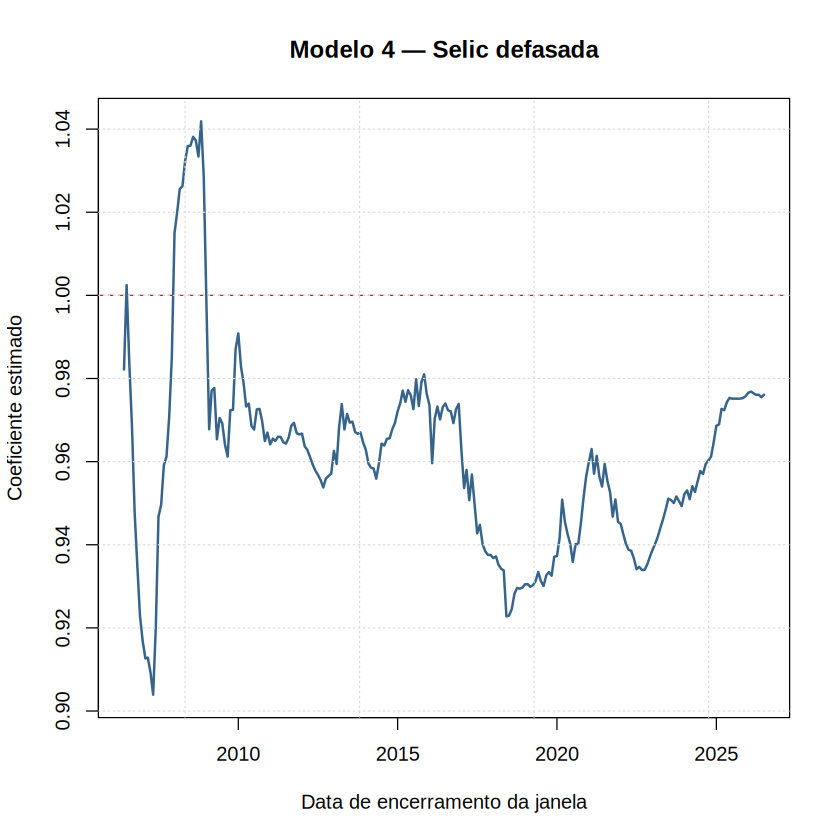

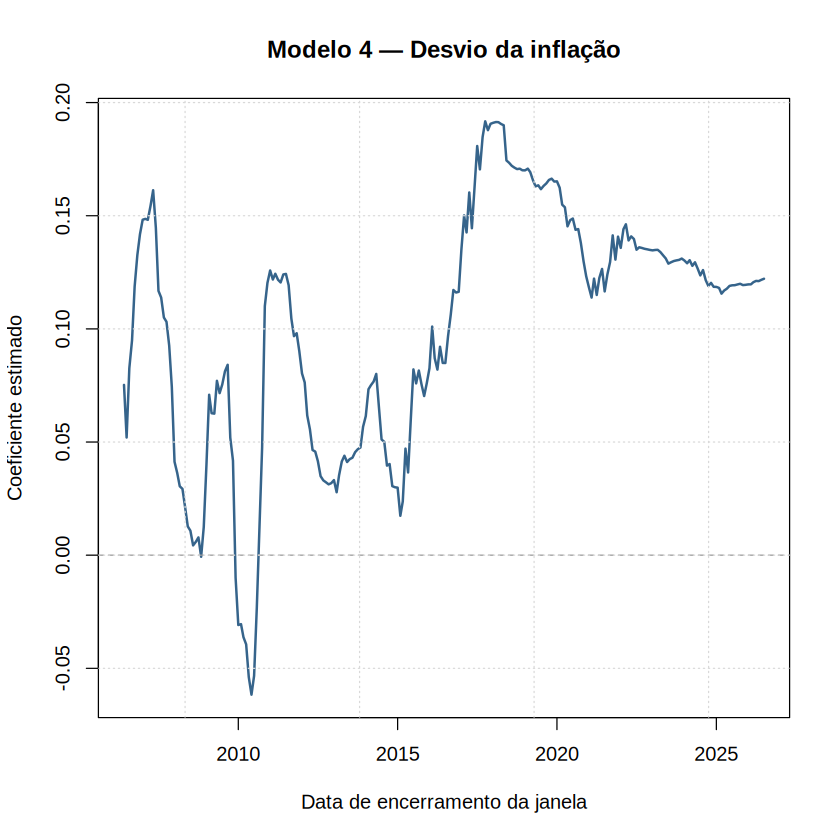

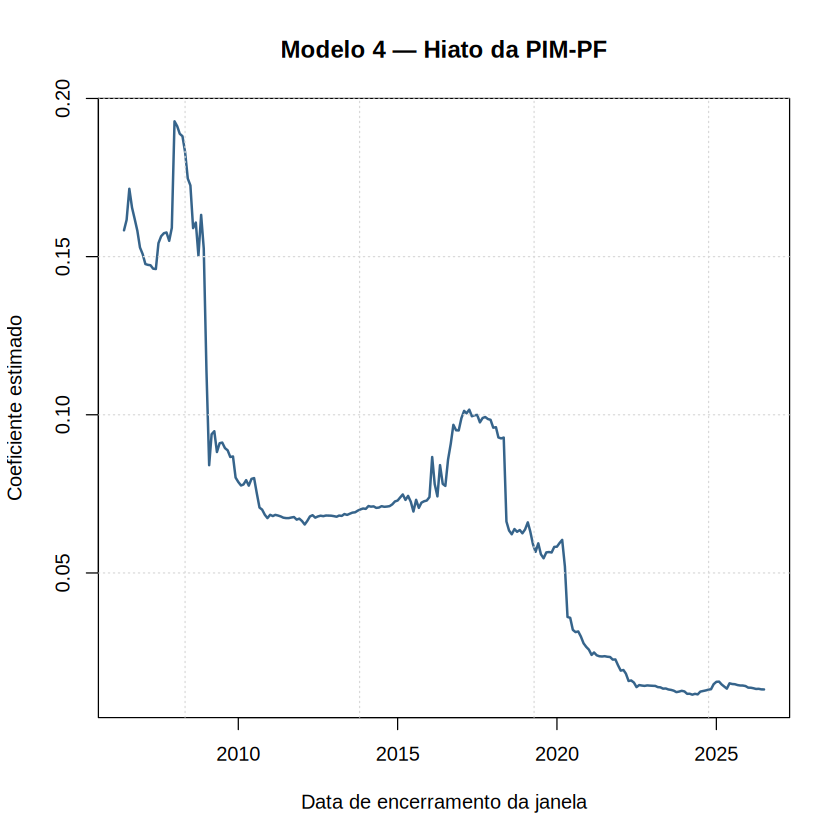

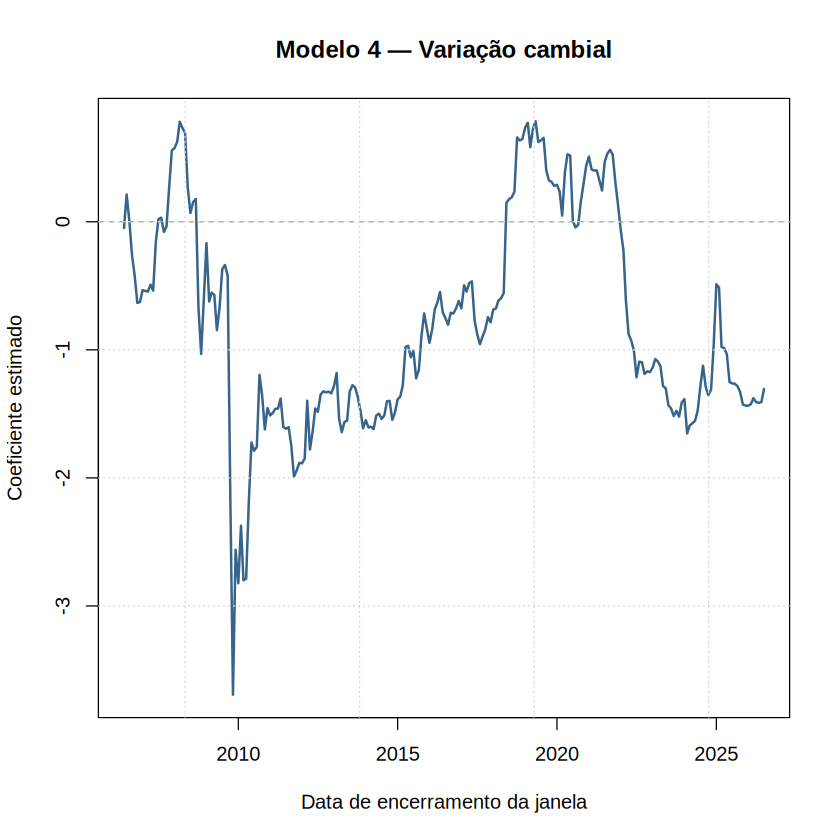

In [ ]:

# ============================================================
# MODELO 4 — GRÁFICOS DAS JANELAS MÓVEIS
# ============================================================

plotar_janela_m4 <- function(coluna, titulo, ylab,
                             referencia_um = FALSE) {

  plot(
    resultados_janelas_m4$Fim,
    resultados_janelas_m4[[coluna]],
    type = "l",
    lwd = 2,
    col = "steelblue4",
    main = titulo,
    xlab = "Data de encerramento da janela",
    ylab = ylab
  )

  abline(
    h = 0,
    col = "gray60",
    lty = 2
  )

  if (referencia_um) {
    abline(
      h = 1,
      col = "firebrick",
      lty = 2
    )
  }

  grid(
    col = "gray85",
    lty = "dotted"
  )
}

plotar_janela_m4(
  "beta_selic",
  "Modelo 4 — Selic defasada",
  "Coeficiente estimado",
  referencia_um = TRUE
)

plotar_janela_m4(
  "beta_inflacao",
  "Modelo 4 — Desvio da inflação",
  "Coeficiente estimado"
)

plotar_janela_m4(
  "beta_hiato",
  "Modelo 4 — Hiato da PIM-PF",
  "Coeficiente estimado"
)

plotar_janela_m4(
  "beta_cambio",
  "Modelo 4 — Variação cambial",
  "Coeficiente estimado"
)



========== TESTE QLR — MODELO 4 ==========

	supF test

data:  fstats_m4
sup.F = 22.538, p-value = 0.009734


========== PONTO DE MÁXIMO DA ESTATÍSTICA F ==========
Maior estatística F: 22.538 
Observação anterior à quebra: 213 
Último mês antes da quebra: 03/2017 
Primeiro mês após a quebra: 04/2017 


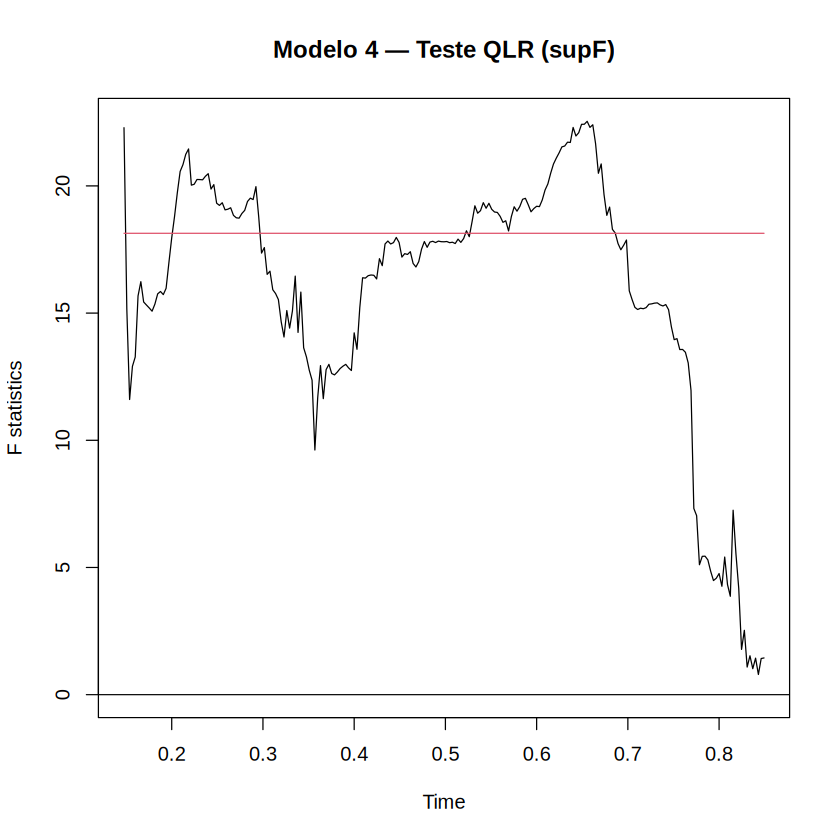

In [ ]:

# ============================================================
# MODELO 4 — TESTE QLR (supF)
# ============================================================

# 1. Estatísticas F para possíveis pontos de quebra
fstats_m4 <- strucchange::Fstats(
  formula_m4,
  data = dados_modelo4,
  from = 0.15,
  to = 0.85
)

# 2. Teste supF
teste_qlr_m4 <- strucchange::sctest(
  fstats_m4,
  type = "supF"
)

cat("\n========== TESTE QLR — MODELO 4 ==========\n")
print(teste_qlr_m4)

# 3. Localizar o maior valor da estatística F
valores_f_m4 <- as.numeric(fstats_m4$Fstats)

posicao_max_m4 <- which.max(valores_f_m4)

estatistica_max_m4 <- valores_f_m4[posicao_max_m4]

# O índice temporal de Fstats é expresso
# como fração da amostra original.
fracao_max_m4 <- as.numeric(
  time(fstats_m4$Fstats)[posicao_max_m4]
)

observacao_quebra_m4 <- round(
  fracao_max_m4 * nrow(dados_modelo4)
)

stopifnot(
  observacao_quebra_m4 >= 1,
  observacao_quebra_m4 < nrow(dados_modelo4)
)

data_antes_quebra_m4 <-
  dados_modelo4$Data[observacao_quebra_m4]

data_depois_quebra_m4 <-
  dados_modelo4$Data[observacao_quebra_m4 + 1]

cat("\n========== PONTO DE MÁXIMO DA ESTATÍSTICA F ==========\n")

cat("Maior estatística F:",
    round(estatistica_max_m4, 6), "\n")

cat("Observação anterior à quebra:",
    observacao_quebra_m4, "\n")

cat("Último mês antes da quebra:",
    format(data_antes_quebra_m4, "%m/%Y"), "\n")

cat("Primeiro mês após a quebra:",
    format(data_depois_quebra_m4, "%m/%Y"), "\n")

# 4. Gráfico do teste
plot(
  fstats_m4,
  main = "Modelo 4 — Teste QLR (supF)"
)


In [ ]:

# ============================================================
# MODELO 4 — BAI-PERRON
# SELEÇÃO DO NÚMERO DE QUEBRAS PELO BIC
# ============================================================

# 1. Estimar as partições candidatas
bp_m4 <- strucchange::breakpoints(
  formula_m4,
  data = dados_modelo4,
  h = 0.15,
  breaks = 5
)

# 2. Resumo dos modelos com 0 a 5 quebras
resumo_bp_m4 <- summary(bp_m4)

cat("\n========== BAI-PERRON — MODELO 4 ==========\n")
print(resumo_bp_m4)

# 3. Extrair os valores de BIC
bic_m4 <- as.numeric(
  resumo_bp_m4$RSS["BIC", ]
)

numero_quebras_m4 <- seq_along(bic_m4) - 1L

tabela_bic_m4 <- data.frame(
  Numero_quebras = numero_quebras_m4,
  BIC = bic_m4
)

cat("\n========== SELEÇÃO PELO BIC ==========\n")
print(
  transform(
    tabela_bic_m4,
    BIC = round(BIC, 4)
  ),
  row.names = FALSE
)

# 4. Selecionar a especificação de menor BIC
n_quebras_otimo_m4 <- numero_quebras_m4[
  which.min(bic_m4)
]

cat(
  "\nNúmero de quebras selecionado pelo BIC:",
  n_quebras_otimo_m4,
  "\n"
)

# 5. Recuperar as posições das quebras
if (n_quebras_otimo_m4 > 0) {

  bp_selecionado_m4 <- strucchange::breakpoints(
    bp_m4,
    breaks = n_quebras_otimo_m4
  )

  posicoes_quebras_m4 <- as.integer(
    bp_selecionado_m4$breakpoints
  )

  tabela_quebras_m4 <- data.frame(
    Quebra = seq_along(posicoes_quebras_m4),
    Observacao = posicoes_quebras_m4,
    Ultimo_mes_antes = format(
      dados_modelo4$Data[posicoes_quebras_m4],
      "%m/%Y"
    ),
    Primeiro_mes_depois = format(
      dados_modelo4$Data[posicoes_quebras_m4 + 1L],
      "%m/%Y"
    )
  )

  cat("\n========== DATAS DAS QUEBRAS ==========\n")
  print(tabela_quebras_m4, row.names = FALSE)

} else {

  posicoes_quebras_m4 <- integer(0)

  cat(
    "\nO BIC selecionou a especificação sem quebras.\n"
  )
}

# 6. Conferência do tamanho dos regimes
limites_m4 <- c(
  0L,
  posicoes_quebras_m4,
  nrow(dados_modelo4)
)

tamanhos_regimes_m4 <- diff(limites_m4)

cat("\n========== TAMANHO DOS REGIMES ==========\n")
print(tamanhos_regimes_m4)

stopifnot(
  sum(tamanhos_regimes_m4) == nrow(dados_modelo4),
  all(tamanhos_regimes_m4 >= floor(0.15 * nrow(dados_modelo4)))
)



========== BAI-PERRON — MODELO 4 ==========

	 Optimal (m+1)-segment partition: 

Call:
breakpoints.formula(formula = formula_m4, h = 0.15, breaks = 5, 
    data = dados_modelo4)

Breakpoints at observation number:
                         
m = 1             213    
m = 2   48 96            
m = 3   48 96     218    
m = 4   48 96 145 220    
m = 5   48 96 145 224 273

Corresponding to breakdates:
                                                                               
m = 1                                                         0.655384615384615
m = 2   0.147692307692308 0.295384615384615                                    
m = 3   0.147692307692308 0.295384615384615                   0.670769230769231
m = 4   0.147692307692308 0.295384615384615 0.446153846153846 0.676923076923077
m = 5   0.147692307692308 0.295384615384615 0.446153846153846 0.689230769230769
            
m = 1       
m = 2       
m = 3       
m = 4       
m = 5   0.84

Fit:
                                  

In [ ]:

# ============================================================
# MODELO 4 — ESTIMAÇÃO POR REGIMES
# BAI-PERRON: DUAS QUEBRAS
# ============================================================

stopifnot(
  n_quebras_otimo_m4 == 2,
  identical(posicoes_quebras_m4, c(48L, 96L))
)

# 1. Definir os limites dos regimes
inicios_m4 <- c(1L, posicoes_quebras_m4 + 1L)

fins_m4 <- c(
  posicoes_quebras_m4,
  nrow(dados_modelo4)
)

# 2. Função de estimação por regime
estimar_regime_m4 <- function(i) {

  dados_regime <- dados_modelo4[
    inicios_m4[i]:fins_m4[i],
  ]

  ajuste <- lm(
    formula_m4,
    data = dados_regime
  )

  V <- sandwich::NeweyWest(
    ajuste,
    lag = NULL,
    prewhite = FALSE,
    adjust = TRUE
  )

  teste <- lmtest::coeftest(
    ajuste,
    vcov. = V
  )

  b <- coef(ajuste)

  alpha <- unname(b["(Intercept)"])
  rho <- unname(b["Selic_L1"])
  beta_pi <- unname(b["Inflacao_L1"])
  beta_y <- unname(b["Hiato_L1"])
  beta_e <- unname(b["Cambio_L1"])

  d <- 1 - rho

  # Parâmetros estruturais
  theta <- c(
    alpha = alpha,
    rho = rho,
    phi_pi = beta_pi / d,
    phi_y = beta_y / d,
    phi_e = beta_e / d
  )

  # Jacobiana do método delta
  J <- matrix(
    0,
    nrow = 5,
    ncol = 5,
    dimnames = list(names(theta), names(b))
  )

  J["alpha", "(Intercept)"] <- 1
  J["rho", "Selic_L1"] <- 1

  J["phi_pi", "Selic_L1"] <- beta_pi / d^2
  J["phi_pi", "Inflacao_L1"] <- 1 / d

  J["phi_y", "Selic_L1"] <- beta_y / d^2
  J["phi_y", "Hiato_L1"] <- 1 / d

  J["phi_e", "Selic_L1"] <- beta_e / d^2
  J["phi_e", "Cambio_L1"] <- 1 / d

  # Inferência estrutural
  V_theta <- J %*% V %*% t(J)

  se_theta <- sqrt(diag(V_theta))

  t_theta <- theta / se_theta

  p_theta <- 2 * pt(
    abs(t_theta),
    df = df.residual(ajuste),
    lower.tail = FALSE
  )

  tabela_estrutural <- data.frame(
    Regime = i,
    Parametro = names(theta),
    Estimativa = as.numeric(theta),
    Erro_padrao_NW = as.numeric(se_theta),
    Valor_p = as.numeric(p_theta)
  )

  tabela_auxiliar <- data.frame(
    Regime = i,
    Variavel = rownames(teste),
    Estimativa = as.numeric(teste[, 1]),
    Erro_padrao_NW = as.numeric(teste[, 2]),
    Valor_p = as.numeric(teste[, 4])
  )

  list(
    Regime = i,
    Inicio = min(dados_regime$Data),
    Fim = max(dados_regime$Data),
    Observacoes = nrow(dados_regime),
    R2 = summary(ajuste)$r.squared,
    Estavel = abs(rho) < 1,
    Auxiliar = tabela_auxiliar,
    Estrutural = tabela_estrutural
  )
}

# 3. Estimar os três regimes
regimes_m4 <- lapply(
  seq_along(inicios_m4),
  estimar_regime_m4
)

# 4. Resumo das amostras
resumo_regimes_m4 <- do.call(
  rbind,
  lapply(regimes_m4, function(x) {
    data.frame(
      Regime = x$Regime,
      Inicio = format(x$Inicio, "%m/%Y"),
      Fim = format(x$Fim, "%m/%Y"),
      Observacoes = x$Observacoes,
      R2 = x$R2,
      Estavel = x$Estavel
    )
  })
)

cat("\n========== RESUMO DOS REGIMES ==========\n")
print(resumo_regimes_m4, row.names = FALSE)

# 5. Coeficientes auxiliares
tabela_auxiliar_regimes_m4 <- do.call(
  rbind,
  lapply(regimes_m4, function(x) x$Auxiliar)
)

cat("\n========== COEFICIENTES AUXILIARES ==========\n")

print(
  transform(
    tabela_auxiliar_regimes_m4,
    Estimativa = round(Estimativa, 6),
    Erro_padrao_NW = round(Erro_padrao_NW, 6),
    Valor_p = signif(Valor_p, 5)
  ),
  row.names = FALSE
)

# 6. Parâmetros estruturais
tabela_estrutural_regimes_m4 <- do.call(
  rbind,
  lapply(regimes_m4, function(x) x$Estrutural)
)

cat("\n========== PARÂMETROS ESTRUTURAIS ==========\n")

print(
  transform(
    tabela_estrutural_regimes_m4,
    Estimativa = round(Estimativa, 6),
    Erro_padrao_NW = round(Erro_padrao_NW, 6),
    Valor_p = signif(Valor_p, 5)
  ),
  row.names = FALSE
)



========== RESUMO DOS REGIMES ==========
 Regime  Inicio     Fim Observacoes        R2 Estavel
      1 07/1999 06/2003          48 0.9510271    TRUE
      2 07/2003 06/2007          48 0.9793240   FALSE
      3 07/2007 07/2026         229 0.9903162    TRUE

========== COEFICIENTES AUXILIARES ==========
 Regime    Variavel Estimativa Erro_padrao_NW     Valor_p
      1 (Intercept)   1.012999       0.689668  1.4916e-01
      1    Selic_L1   0.929033       0.039773  4.6431e-26
      1 Inflacao_L1   0.158394       0.059082  1.0370e-02
      1    Hiato_L1   0.003891       0.048070  9.3586e-01
      1   Cambio_L1   1.280905       2.382555  5.9361e-01
      2 (Intercept)  -1.025291       0.718199  1.6063e-01
      2    Selic_L1   1.058236       0.045334  4.7634e-26
      2 Inflacao_L1  -0.155775       0.058915  1.1388e-02
      2    Hiato_L1   0.224874       0.044830  9.6020e-06
      2   Cambio_L1  -3.197509       1.621731  5.5104e-02
      3 (Intercept)   0.144722       0.080379  7.3126e-02

In [ ]:

# ============================================================
# MODELO 4 — TESTES DE CHOW
# DATAS INSTITUCIONAIS PREDEFINIDAS
# ============================================================

# 1. Função para o teste de Chow clássico
teste_chow_m4 <- function(data_quebra, identificacao) {

  data_quebra <- as.Date(data_quebra)

  dados_antes <- dados_modelo4[
    dados_modelo4$Data < data_quebra,
  ]

  dados_depois <- dados_modelo4[
    dados_modelo4$Data >= data_quebra,
  ]

  n1 <- nrow(dados_antes)
  n2 <- nrow(dados_depois)

  # Número de parâmetros estimados, incluindo intercepto
  k <- length(coef(modelo4))

  if (n1 <= k || n2 <= k) {
    stop("Amostra insuficiente para o teste de Chow.")
  }

  # Modelo restrito: coeficientes comuns
  rss_restrito <- sum(resid(modelo4)^2)

  # Modelos irrestritos: coeficientes separados
  ajuste_antes <- lm(
    formula_m4,
    data = dados_antes
  )

  ajuste_depois <- lm(
    formula_m4,
    data = dados_depois
  )

  rss_irrestrito <-
    sum(resid(ajuste_antes)^2) +
    sum(resid(ajuste_depois)^2)

  # Estatística F clássica
  F_chow <- (
    (rss_restrito - rss_irrestrito) / k
  ) / (
    rss_irrestrito / (n1 + n2 - 2 * k)
  )

  p_chow <- pf(
    F_chow,
    df1 = k,
    df2 = n1 + n2 - 2 * k,
    lower.tail = FALSE
  )

  data.frame(
    Transicao = identificacao,
    Data_quebra = format(data_quebra, "%m/%Y"),
    N_antes = n1,
    N_depois = n2,
    Estatistica_F = F_chow,
    Valor_p = p_chow,
    Significativo_5pct = p_chow < 0.05
  )
}

# 2. Aplicação às quatro transições
resultados_chow_m4 <- do.call(
  rbind,
  list(
    teste_chow_m4(
      "2011-01-01",
      "Tombini"
    ),
    teste_chow_m4(
      "2016-06-01",
      "Goldfajn"
    ),
    teste_chow_m4(
      "2019-03-01",
      "Campos Neto"
    ),
    teste_chow_m4(
      "2025-01-01",
      "Galipolo"
    )
  )
)

cat("\n========== TESTES DE CHOW — MODELO 4 ==========\n")

print(
  transform(
    resultados_chow_m4,
    Estatistica_F = round(Estatistica_F, 6),
    Valor_p = signif(Valor_p, 6)
  ),
  row.names = FALSE
)

# 3. Validação das amostras
stopifnot(
  all(
    resultados_chow_m4$N_antes +
      resultados_chow_m4$N_depois == 325
  )
)



========== TESTES DE CHOW — MODELO 4 ==========
   Transicao Data_quebra N_antes N_depois Estatistica_F     Valor_p
     Tombini     01/2011     138      187      3.268528 0.006820620
    Goldfajn     06/2016     203      122      4.259594 0.000920355
 Campos Neto     03/2019     236       89      3.072648 0.010061800
    Galipolo     01/2025     306       19      1.630728 0.151448000
 Significativo_5pct
               TRUE
               TRUE
               TRUE
              FALSE
